# Practice Session 05: PageRank

# 1. Read host names

In [1]:
import io
import gzip
import csv
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
INPUT_NODES_FILENAME = "webspam_uk2007-nodes.csv.gz"
INPUT_EDGES_FILENAME = "webspam_uk2007-edges.csv.gz"

In [3]:
id2name = {}
name2id = {}
id2label = {}

with gzip.open(INPUT_NODES_FILENAME, "rt", encoding="utf-8") as input_file:
    reader = csv.DictReader(input_file, delimiter=',', quotechar='"')
    for record in reader:
        nodeid = int(record["nodeid"])
        hostname = record["hostname"]
        label = record["label"]
        
        id2name[nodeid] = hostname
        name2id[hostname] = nodeid
        id2label[nodeid] = label

In [4]:
# Leave as-is

print("Number of hosts: %s" % len(id2name))
print("%s: %s" % (id2name[873], id2label[873]))
print("%s: %s" % (id2name[105715], id2label[105715]))

Number of hosts: 114529
bbc.co.uk: nonspam
www.top-mobile-phones.co.uk: spam


In [5]:
label_counts = {'spam': 0, 'nonspam': 0, 'unlabeled': 0}

for label in id2label.values():
    label_counts[label] += 1

total_hosts = len(id2label)
label_percentages = {label: (count / total_hosts) * 100 for label, count in label_counts.items()}
for label, count in label_counts.items():
    print(f"{label}: {count:,} ({label_percentages[label]:.1f}%)")

spam: 344 (0.3%)
nonspam: 5,709 (5.0%)
unlabeled: 108,476 (94.7%)


In [6]:
spammywords = ['credit', 'free', 'mortgage', 'jackpot', 'casino', 'wealthy', 'luxury', 'shop', 'replica', 'finance', 'debt', 'loan', 'discount', 'escort', 'xx', 'girl', 'mistress', 'important', 'attention']
g = nx.DiGraph()

with gzip.open(INPUT_EDGES_FILENAME, "rt", encoding="utf-8") as input_file:
    reader = csv.DictReader(input_file, delimiter=',', quotechar='"')
    for record in reader:
        source = int(record["source"])
        destination = int(record["destination"])
        weight = int(record["weight"])

        if (any(word in id2name[source] for word in spammywords) or any(word in id2name[destination] for word in spammywords)) and \
           (id2label[source] in ['spam', 'nonspam']) and (id2label[destination] in ['spam', 'nonspam']):
            g.add_edge(id2name[source], id2name[destination])

print("Number of nodes in the subgraph:", g.number_of_nodes())

Number of nodes in the subgraph: 172


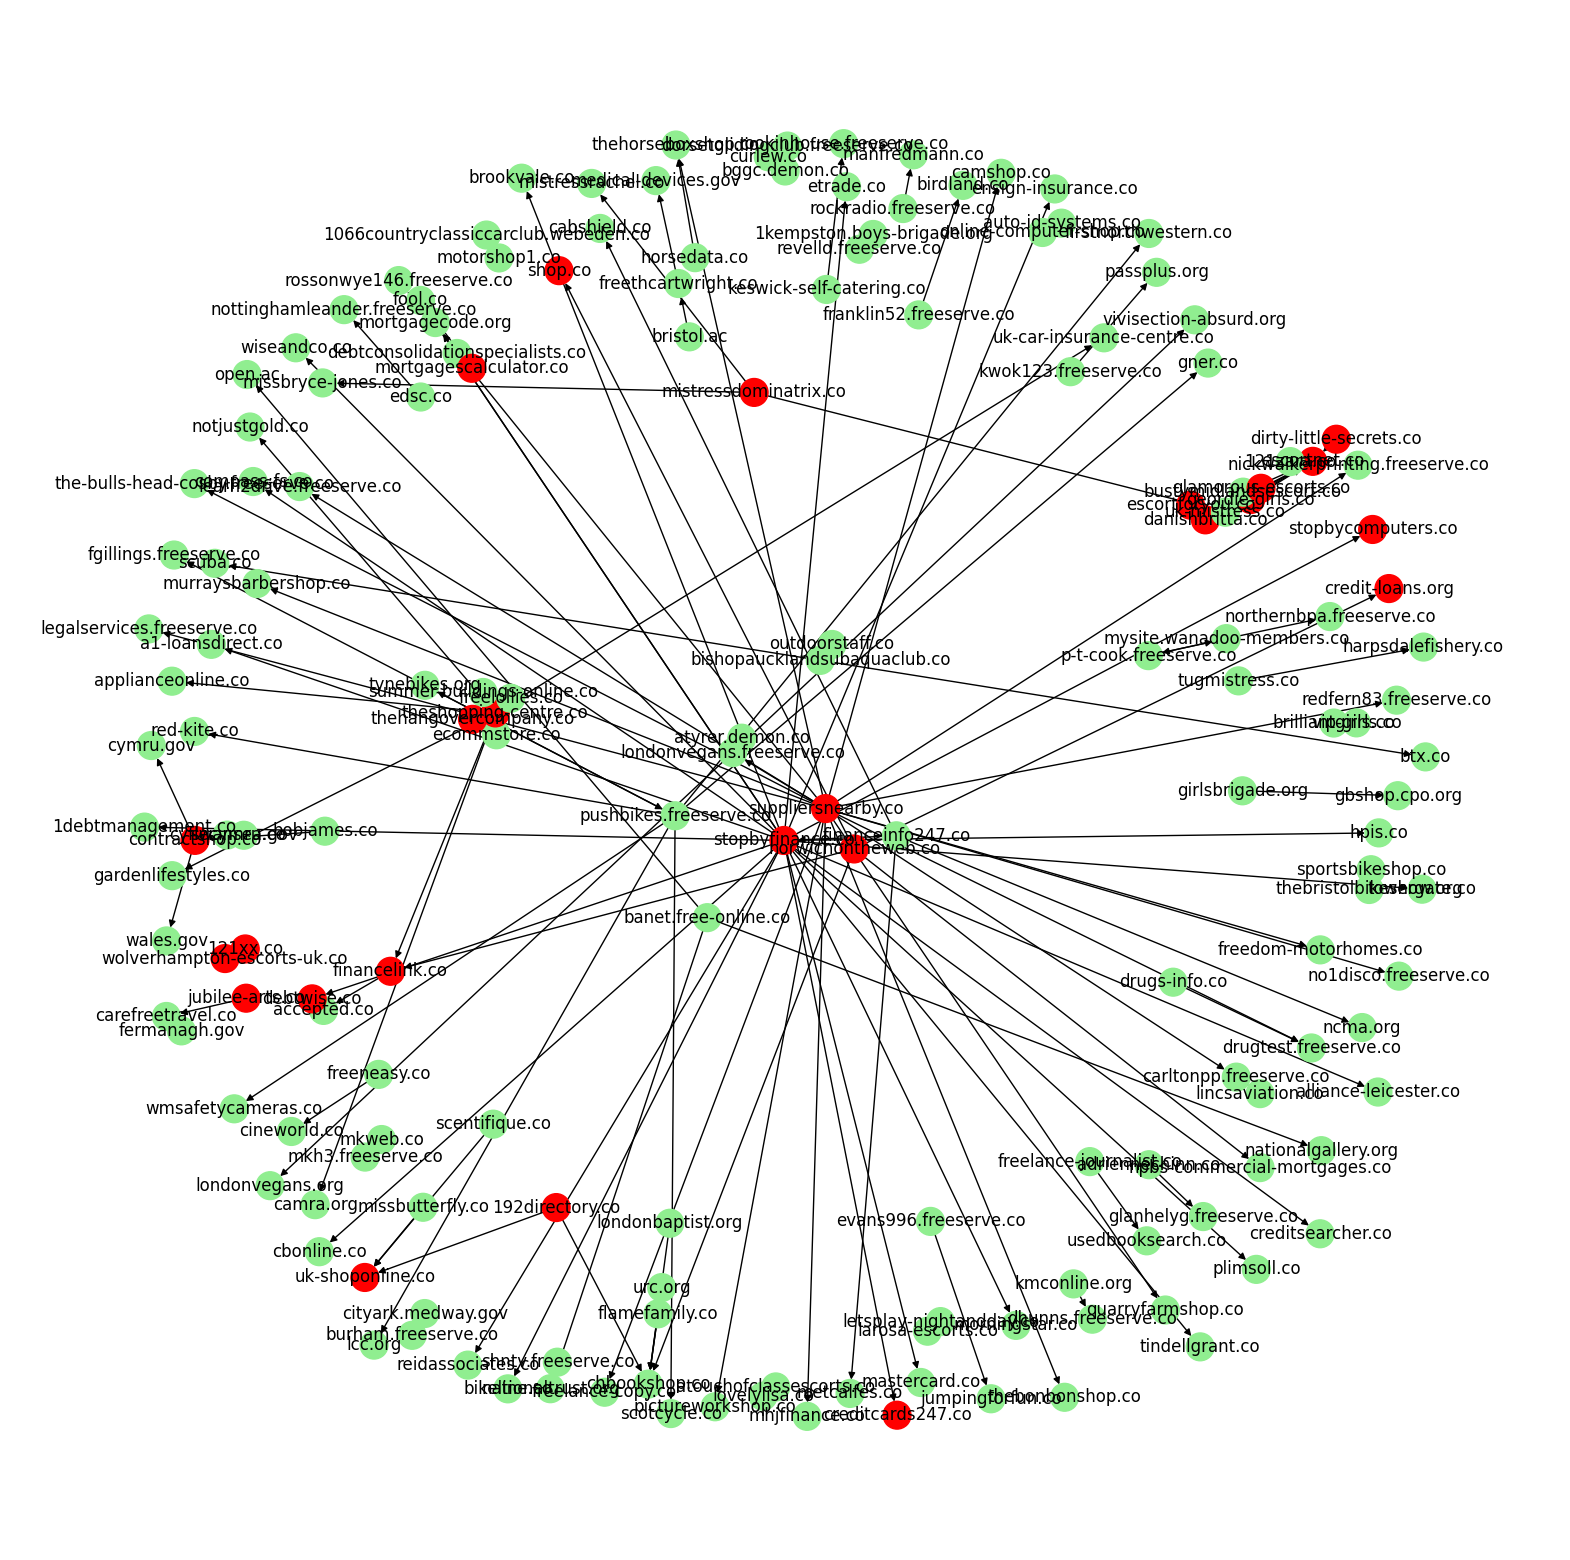

In [7]:
# Leave this code as-is, or modify slightly

colors = []
hostname_converted = {}

for hostname in g.nodes():
    # Assign colors to nodes according to spam/nonspam labels
    if id2label[name2id[hostname]] == 'spam':
        colors.append('red')
    elif id2label[name2id[hostname]] == 'nonspam':
        colors.append('lightgreen')
    else:
        colors.append('white')
    
    # Shorten the hostnames to generate labels    
    label = hostname.replace("www.", "").replace(".uk", "")
    hostname_converted[hostname] = label
    
# Notice that if you re-run this cell the layout will be different every time
plt.figure(figsize=(20, 20))
plt.axis('off')
pos = nx.spring_layout(g)
nx.draw_networkx(g, pos, with_labels=True, node_size=400, node_color=colors, labels=hostname_converted)

The plot above shows a subgraph of the network, with nodes colored based on their labels, such as spam or non-spam. We can observe that although the majority of the nodes are non-spam, there is a cluster of three central nodes in the middle of the graph that belong to the spam group. These nodes are connected to both spam and non-spam nodes and play a significant role in the graph.

# 2. Compute the degree of each node

In [8]:
# Leave this code as-is

id2degree = {}
N = len(id2name)
for nodeid in range(N):
    id2degree[nodeid] = 0

In [9]:
with gzip.open(INPUT_EDGES_FILENAME, "rt", encoding="utf-8") as input_file:
    reader = csv.DictReader(input_file, delimiter=',', quotechar='"')
    for record in reader:
        source = int(record["source"])
        destination = int(record["destination"])
        weight = int(record["weight"])
        
        id2degree[source] += 1

In [10]:
# Leave this cell as-is

for nodeid in [61914, 479, 62730]:
    print("%s: degree %d" % (id2name[nodeid], id2degree[nodeid]))

www.instrumentfinance.co.uk: degree 262
amazon.co.uk: degree 6
www.iso9000uk.co.uk: degree 38


# 3. Compute PageRank

In [11]:
# Leave this cell as-is

ITERATIONS = 25
ALPHA = 0.91

pagerank = [1.0/N] * N
pagerank_aux = [0.0] * N

In [15]:
for iteration in range(ITERATIONS):
    print("Iteration %d of %d" % (iteration+1, ITERATIONS))

    pagerank_aux = [0.0] * N

    with gzip.open(INPUT_EDGES_FILENAME, "rt", encoding="utf-8") as input_file:
        reader = csv.DictReader(input_file)
        for record in reader:
            source = int(record['source'])
            destination = int(record['destination'])

            if id2degree[source] > 0:
                pagerank_aux[destination] += pagerank[source] / id2degree[source]
    new_pagerank = [ALPHA * pagerank_aux[i] + (1.0 - ALPHA) / N for i in range(N)]
    norm_factor = sum(new_pagerank)
    new_pagerank = [pr / norm_factor for pr in new_pagerank]
    delta = sum(abs(new_pagerank[i] - pagerank[i]) for i in range(N))
    print(f"Delta: {delta:.4f}")
    pagerank = new_pagerank

Iteration 1 of 25
Delta: 0.0302
Iteration 2 of 25
Delta: 0.0240
Iteration 3 of 25
Delta: 0.0197
Iteration 4 of 25
Delta: 0.0169
Iteration 5 of 25
Delta: 0.0153
Iteration 6 of 25
Delta: 0.0147
Iteration 7 of 25
Delta: 0.0146
Iteration 8 of 25
Delta: 0.0145
Iteration 9 of 25
Delta: 0.0145
Iteration 10 of 25
Delta: 0.0146
Iteration 11 of 25
Delta: 0.0147
Iteration 12 of 25
Delta: 0.0148
Iteration 13 of 25
Delta: 0.0150
Iteration 14 of 25
Delta: 0.0151
Iteration 15 of 25
Delta: 0.0153
Iteration 16 of 25
Delta: 0.0155
Iteration 17 of 25
Delta: 0.0157
Iteration 18 of 25
Delta: 0.0159
Iteration 19 of 25
Delta: 0.0161
Iteration 20 of 25
Delta: 0.0162
Iteration 21 of 25
Delta: 0.0164
Iteration 22 of 25
Delta: 0.0166
Iteration 23 of 25
Delta: 0.0168
Iteration 24 of 25
Delta: 0.0170
Iteration 25 of 25
Delta: 0.0171


# 4. Nodes with largest values of PageRank

In [16]:
def print_top_pagerank_hosts(pagerank, id2name, id2label, top_n=20):
    hosts_by_score = sorted(enumerate(pagerank), key=lambda x: x[1], reverse=True)[:top_n]
    for nodeid, score in hosts_by_score:
        print(f"{nodeid}: {id2name[nodeid]}, {id2label[nodeid]}, {score:.6f}")

print_top_pagerank_hosts(pagerank, id2name, id2label)

81634: www.opsi.gov.uk, unlabeled, 0.006183
65466: www.kelkoo.co.uk, unlabeled, 0.004244
9215: www.aa-roundabout.org.uk, unlabeled, 0.004140
12326: www.alcoholics-anonymous.org.uk, unlabeled, 0.003975
60715: www.ico.gov.uk, unlabeled, 0.003674
6475: shopping.kelkoo.co.uk, unlabeled, 0.003658
10990: www.adobe.co.uk, unlabeled, 0.003251
42757: www.dti.gov.uk, unlabeled, 0.002973
39774: www.defra.gov.uk, unlabeled, 0.002867
40999: www.direct.gov.uk, unlabeled, 0.002481
34406: www.communities.gov.uk, unlabeled, 0.002474
40559: www.dfes.gov.uk, unlabeled, 0.002362
37012: www.croner.co.uk, unlabeled, 0.002168
29600: www.cch.co.uk, unlabeled, 0.002151
40612: www.dh.gov.uk, unlabeled, 0.002015
751: audiovisual.kelkoo.co.uk, unlabeled, 0.001934
5169: news.bbc.co.uk, unlabeled, 0.001903
58631: www.hmso.gov.uk, unlabeled, 0.001896
51107: www.fsa.gov.uk, unlabeled, 0.001864
4478: listserv.weatheronline.co.uk, unlabeled, 0.001820


(1) ->We can observe that these top sites play an important role in the network, which explains their high PageRank. Most of them belong to the government (they end with .gov), while others are commercial sites (ending with .co). It is therefore expected that they have significant influence within the network and enjoy high popularity.

(2)

Government: 10/20 = 50%

Commercial: 10/20 = 50%

Educational: 0/20 = 0% (none ending with .edu)

# 5. Run non-spam PageRank

In [21]:
id2nsdegree = {nodeid: 0 for nodeid in range(N)}

with gzip.open(INPUT_EDGES_FILENAME, "rt", encoding="utf-8") as input_file:
    reader = csv.DictReader(input_file, delimiter=',', quotechar='"')
    for record in reader:
        source = int(record["source"])
        destination = int(record["destination"])
        
        if id2label[source] != "spam" and id2label[destination] != "spam":
            id2nsdegree[source] += 1

In [26]:
# Leave this cell as-is

for nodeid in [61914, 479, 62730]:
    print("%s: normal degree %d nospam degree %d" % (id2name[nodeid], id2degree[nodeid], id2nsdegree[nodeid]))

www.instrumentfinance.co.uk: normal degree 262 nospam degree 258
amazon.co.uk: normal degree 6 nospam degree 6
www.iso9000uk.co.uk: normal degree 38 nospam degree 37


In [31]:
nspagerank = [1.0/N] * N
nspagerank_aux = [0.0] * N

for iteration in range(ITERATIONS):
    print("Iteration %d of %d" % (iteration+1, ITERATIONS))

    nspagerank_aux = [0.0] * N

    with gzip.open(INPUT_EDGES_FILENAME, "rt", encoding="utf-8") as input_file:
        reader = csv.DictReader(input_file)
        for record in reader:
            source = int(record['source'])
            destination = int(record['destination'])

            if id2label[source] != "spam" and id2label[destination] != "spam" and id2nsdegree[source] > 0:
                nspagerank_aux[destination] += nspagerank[source] / id2nsdegree[source]

    new_nspagerank = [ALPHA * nspagerank_aux[i] + (1.0 - ALPHA) / N for i in range(N)]
    norm_factor = sum(new_nspagerank)
    new_nspagerank = [pr / norm_factor for pr in new_nspagerank]
    delta = sum(abs(new_nspagerank[i] - nspagerank[i]) for i in range(N))
    print(f"Delta: {delta:.4f}")
    nspagerank = new_nspagerank

Iteration 1 of 25
Delta: 1.1480
Iteration 2 of 25
Delta: 0.4816
Iteration 3 of 25
Delta: 0.2267
Iteration 4 of 25
Delta: 0.1260
Iteration 5 of 25
Delta: 0.0799
Iteration 6 of 25
Delta: 0.0548
Iteration 7 of 25
Delta: 0.0400
Iteration 8 of 25
Delta: 0.0303
Iteration 9 of 25
Delta: 0.0240
Iteration 10 of 25
Delta: 0.0197
Iteration 11 of 25
Delta: 0.0169
Iteration 12 of 25
Delta: 0.0153
Iteration 13 of 25
Delta: 0.0147
Iteration 14 of 25
Delta: 0.0146
Iteration 15 of 25
Delta: 0.0146
Iteration 16 of 25
Delta: 0.0146
Iteration 17 of 25
Delta: 0.0147
Iteration 18 of 25
Delta: 0.0148
Iteration 19 of 25
Delta: 0.0149
Iteration 20 of 25
Delta: 0.0151
Iteration 21 of 25
Delta: 0.0153
Iteration 22 of 25
Delta: 0.0154
Iteration 23 of 25
Delta: 0.0156
Iteration 24 of 25
Delta: 0.0158
Iteration 25 of 25
Delta: 0.0160


In [32]:
print_top_pagerank_hosts(nspagerank, id2name, id2label)

81634: www.opsi.gov.uk, unlabeled, 0.006532
60715: www.ico.gov.uk, unlabeled, 0.003839
65466: www.kelkoo.co.uk, unlabeled, 0.003398
10990: www.adobe.co.uk, unlabeled, 0.003397
42757: www.dti.gov.uk, unlabeled, 0.003130
12326: www.alcoholics-anonymous.org.uk, unlabeled, 0.003113
39774: www.defra.gov.uk, unlabeled, 0.003015
6475: shopping.kelkoo.co.uk, unlabeled, 0.002899
9215: www.aa-roundabout.org.uk, unlabeled, 0.002836
40999: www.direct.gov.uk, unlabeled, 0.002611
34406: www.communities.gov.uk, unlabeled, 0.002609
40559: www.dfes.gov.uk, unlabeled, 0.002490
40612: www.dh.gov.uk, unlabeled, 0.002125
58631: www.hmso.gov.uk, unlabeled, 0.001997
5169: news.bbc.co.uk, unlabeled, 0.001991
51107: www.fsa.gov.uk, unlabeled, 0.001953
77619: www.nationalrail.co.uk, unlabeled, 0.001903
59140: www.homeoffice.gov.uk, unlabeled, 0.001807
59870: www.hse.gov.uk, unlabeled, 0.001734
43141: www.dwp.gov.uk, unlabeled, 0.001727


We can observe that there are not many differences between the two lists. This migth be because government and commercial sites tend to have high influence because they attract many legitimate links compared to spam websites.

# 6. Compute spam gain

In [29]:
spam_gain = [(nodeid, pagerank[nodeid] / nspagerank[nodeid] if nspagerank[nodeid] > 0 else float('inf')) for nodeid in range(N)]

top_spam_gain_hosts = sorted(spam_gain, key=lambda x: x[1], reverse=True)[:50]

for i, (nodeid, gain) in enumerate(top_spam_gain_hosts):
    print(f"{i+1}. {id2name[nodeid]} (Label: {id2label[nodeid]})")
    print(f"   Gain: {gain:.2f}")
    print(f"   PageRank: {pagerank[nodeid]:.2e}")
    print(f"   No-spam PageRank: {nspagerank[nodeid]:.2e}")

1. www.into.demon.co.uk (Label: spam)
   Gain: 173.87
   PageRank: 1.54e-04
   No-spam PageRank: 8.85e-07
2. www.aili.co.uk (Label: unlabeled)
   Gain: 156.94
   PageRank: 1.67e-04
   No-spam PageRank: 1.06e-06
3. www.missionfish.org.uk (Label: spam)
   Gain: 139.84
   PageRank: 1.24e-04
   No-spam PageRank: 8.85e-07
4. www.statistics.006.free-counter.co.uk (Label: spam)
   Gain: 132.96
   PageRank: 1.18e-04
   No-spam PageRank: 8.85e-07
5. www.escortnet.co.uk (Label: spam)
   Gain: 118.53
   PageRank: 1.05e-04
   No-spam PageRank: 8.85e-07
6. www.hertfordshiremobilediscos.co.uk (Label: spam)
   Gain: 108.83
   PageRank: 9.63e-05
   No-spam PageRank: 8.85e-07
7. www.jlc.me.uk (Label: spam)
   Gain: 93.86
   PageRank: 8.31e-05
   No-spam PageRank: 8.85e-07
8. www.geordie-girls.co.uk (Label: spam)
   Gain: 44.55
   PageRank: 3.94e-05
   No-spam PageRank: 8.85e-07
9. www.kompass.co.uk (Label: spam)
   Gain: 33.90
   PageRank: 3.00e-05
   No-spam PageRank: 8.85e-07
10. www.uk-shoponline.co

We can cleary observe how most of the pages on this list are spam websites. Most of these websites have a higher rankings in the spam PageRank compared to the non-spam version. The gain value  indicates how much these websites benefited from spam links.

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>